In [24]:
# import json

import numpy as np
# import osmnx as ox
import pandas as pd
import geopandas as gpd
from shapely import wkt

# import lts_functions
import LTS_OSM
# import LTS_plot

import matplotlib.pyplot as plt

%load_ext autoreload
%autoreload 2

CRS = 'EPSG:2805'
AREA_CONVERT = 3.861022e-7 # Convert from m^2 to mi^2
COLOR_SCALE = ['#007191', '#62c8d3', '#f47a00', '#d31f11', 'grey']

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [2]:
# Load LTS csv
# gdf = LTS_OSM.read_lts_csv(r'data\GreaterBoston_4_all_lts.csv')
gdf = LTS_OSM.read_lts_csv(r'data\Boston_4_all_lts.csv')

gdf.to_crs(CRS, inplace=True)

gdf['geometry_centroid'] = gdf.centroid
gdf['geometry_way'] = gdf['geometry']

# Reduce bi-directional line pairs
gdf.drop_duplicates(subset=['osmid', 'geometry_centroid'], inplace=True)

In [3]:
geojsonFolder = '../osm-bikeparking/'

city = gpd.read_file(f'{geojsonFolder}data_cities.geojson')
hood = gpd.read_file(f'{geojsonFolder}data_neighborhoods.geojson')
council = gpd.read_file(f'{geojsonFolder}data_council_boston.json')

city.to_crs(CRS, inplace=True)
hood.to_crs(CRS, inplace=True)
council.to_crs(CRS, inplace=True)

# Pre-process city data
city['population'] = city['population'].str.replace(r'\D', '', regex=True).astype(float) # Remove non-digit values from populations, e.g. commas
city.rename(columns={'name': 'city'}, inplace=True)
city['population'] = city['population'].fillna(-1)
city = city.astype({"population": "int"})
city['area_sqmi'] = city.area * AREA_CONVERT # https://spatialreference.org/ref/epsg/2805/

# Pre-process neighborhood data
hood.rename(columns={'name': 'neighborhood'}, inplace=True)
hood['area_sqmi'] = hood.area * AREA_CONVERT # https://spatialreference.org/ref/epsg/2805/

hoodCentroid = hood[['neighborhood', 'geometry']]
hoodCentroid['geometry'] = hood.centroid
hoodCentroid = hoodCentroid.sjoin(city[['city','geometry']], how='inner', predicate='intersects')
hoodCentroid.set_index('neighborhood', inplace=True)
hood = hood.join(hoodCentroid['city'], on='neighborhood')
# hood = hood.join(hoodCentroid['city'], on='neighborhood', lsuffix='suf')

# Pre-process city council districts data
council['area_sqmi'] = council.area * AREA_CONVERT # https://spatialreference.org/ref/epsg/2805/

In [4]:
for x in gdf.columns:
    print(x)

osmid
highway
maxspeed
name
oneway
surface
lane_markings
lanes
turn:lanes
bridge
foot
layer
width
bicycle
lanes:forward
lanes:backward
turn:lanes:backward
parking:lane:left
parking:lane:right
expressway
maxspeed:type
short_name
sidewalk
cycleway:lane
cycleway:right
parking:left
parking:right
parking:right:orientation
cycleway:right:buffer
service
cycleway:left
cycleway:right:lane
cycleway:left:buffer
cycleway:left:lane
turn:lanes:forward
motor_vehicle
oneway:bicycle
cycleway:left:oneway
footway
crossing
segregated
access
sidewalk:left
sidewalk:right
incline
covered
shoulder
ramp
parking:left:orientation
start_date
construction
parking:lane:left:parallel
alt_name
crossing:markings
description
cycleway:right:oneway
motor_vehicle:conditional
junction
busway:left
crossing:island
crossing:signals
placement
tracktype
oneway:conditional
name:en
sidewalk:right:surface
bus
psv
access:conditional
vehicle
traffic_calming
parking:condition:left
lanes:bus:backward
lanes:bus:forward
busway:right
tra

In [5]:
gdfSmall = gdf[['osmid', 'geometry_centroid', 'geometry_way', 'LTS_fwd', 'LTS_rev', 'geometry', 'highway']]
gdfSmall['length'] = gdfSmall.length
gdfSmall['geometry'] = gdfSmall['geometry_centroid']


gdfCity = gdfSmall.sjoin(city[['city','geometry']], how='inner', predicate='intersects')
gdfHood = gdfSmall.sjoin(hood[['neighborhood','geometry']], how='inner', predicate='intersects')
gdfCouncil = gdfSmall.sjoin(council[['LONGNAME', 'Councilor','geometry']], how='inner', predicate='intersects')

In [6]:

sumFwd = gdfCity.groupby(['city', 'LTS_fwd', 'highway'])['length'].sum().rename_axis(['city', 'LTS', 'highway'])
sumRev = gdfCity.groupby(['city', 'LTS_rev', 'highway'])['length'].sum().rename_axis(['city', 'LTS', 'highway'])
sumLTS = sumFwd + sumRev
sumLTS.loc[['Cambridge','Boston','Somerville','Brookline']].to_csv('total_city.csv')

sumFwd = gdfHood.groupby(['neighborhood', 'LTS_fwd', 'highway'])['length'].sum().rename_axis(['neighborhood', 'LTS', 'highway'])
sumRev = gdfHood.groupby(['neighborhood', 'LTS_rev', 'highway'])['length'].sum().rename_axis(['neighborhood', 'LTS', 'highway'])
sumLTS = sumFwd + sumRev
sumLTS.to_csv('total_neighborhood.csv')

sumFwd = gdfCouncil.groupby(['LONGNAME', 'Councilor', 'LTS_fwd', 'highway'])['length'].sum().rename_axis(['District', 'Councilor', 'LTS', 'highway'])
sumRev = gdfCouncil.groupby(['LONGNAME', 'Councilor', 'LTS_rev', 'highway'])['length'].sum().rename_axis(['District', 'Councilor', 'LTS', 'highway'])
sumLTS = sumFwd + sumRev
sumLTS.to_csv('total_council.csv')
sumLTS = sumLTS.reset_index()

gdfCouncilFilter = gdfCouncil[gdfCouncil['highway']!='residential']
sumFwd = gdfCouncilFilter.groupby(['LONGNAME', 'Councilor', 'LTS_fwd'])['length'].sum().rename_axis(['District', 'Councilor', 'LTS'])
sumRev = gdfCouncilFilter.groupby(['LONGNAME', 'Councilor', 'LTS_rev'])['length'].sum().rename_axis(['District', 'Councilor', 'LTS'])
sumLTS = sumFwd + sumRev
sumLTS = sumLTS.reset_index()
sumLTS = sumLTS[sumLTS['LTS']!='0.0']
sumLTS.to_csv('total_council_filter.csv')

In [7]:
sumLTS

,District,Councilor,LTS,length
1,District 1,Gabriela Coletta,1.0,172541.282091
2,District 1,Gabriela Coletta,2.0,132738.723888
3,District 1,Gabriela Coletta,3.0,70827.701264
4,District 1,Gabriela Coletta,4.0,19930.995769
6,District 2,Ed Flynn,1.0,107570.517486
7,District 2,Ed Flynn,2.0,123188.321281
8,District 2,Ed Flynn,3.0,74591.764082
9,District 2,Ed Flynn,4.0,29309.847139
11,District 3,John Fitzgerald,1.0,140214.435090
12,District 3,John Fitzgerald,2.0,189327.900848


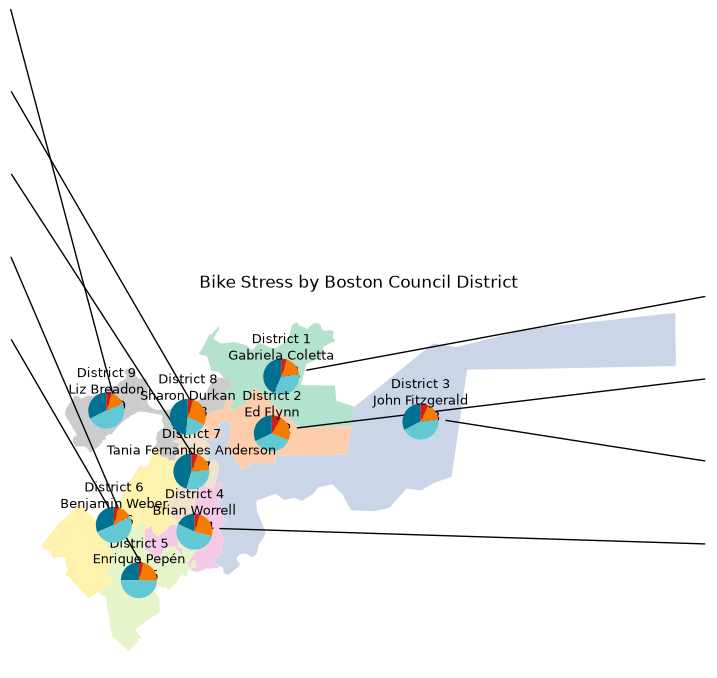

In [121]:
fig, ax = plt.subplots(
    1,1, 
    figsize=(9,9),
    )

council.plot(
    cmap='Pastel2',
    ax=ax,
    aspect='equal',

    )
# ax.set_xticklabels([])
# ax.set_yticklabels([])
ax.axis(False)
ax.set_title('Bike Stress by Boston Council District')

bbox = ax.get_position()  
trans = ax.transData + fig.transFigure.inverted()

regionCentroid = council.centroid.get_coordinates(ignore_index=True)
for r, region in council.iterrows():
    # print(region)
    coords = regionCentroid.iloc[r]
    x_fig, y_fig = trans.transform(coords)
    width, height = np.array([1.0, 1.0]) * 0.05 # Size of pie charts, % of plot

    # print(f'{region['LONGNAME']} {x_fig=:.2f} {y_fig=:.2f} {width=:.2f} {height=:.2f}')

    half = (r+1) // ((len(council)+1)/2)
    posSide = (1 - half, 1 - (r/(len(council)/2))*(1-half) + half*(r/(len(council)/2)-1))

    ax.annotate(
        region['SHORTNAME'],
        # xy=(coords), xycoords='data',
        # xytext=(0.9, 1 - (0.1 * r)), textcoords='axes fraction',
        xytext=(coords), textcoords='data',
        xy=posSide, xycoords='axes fraction',
        arrowprops=dict(arrowstyle="-",
                        connectionstyle="arc3")
        )

    pie_ax = fig.add_axes([x_fig - width/2 , y_fig - height/2, width, height], aspect='equal')
    # pie_ax = fig.add_axes([x_fig - width/2 , y_fig - height/2, width, height], aspect='equal')
    pie_ax.pie(sumLTS[sumLTS['District']==region['LONGNAME']]['length'], startangle=90, colors=COLOR_SCALE)
    pie_ax.set_title(f'{region['LONGNAME']}\n{region['Councilor']}', y=1.0, pad=-4, fontdict={'size': 9})

# axpie.pie(sumLTS[sumLTS['District']=='District 1']['length'])

# plot.show()

In [9]:
council[council['LONGNAME']=='District 1'].centroid.get_coordinates(ignore_index=True).iloc[0]

x    239216.017627
y    902205.545140
Name: 0, dtype: float64

In [151]:
for r in [0,1,2,3,4,5,6,7,8]:
    half = (r+1) // ((len(council)+1)/2)
    print(half, (1-half)*(1 - (r+1)/(len(council)/2)) + half*(((r-r/2)-1)/(len(council)/2)),r-r/2-1)

0.0 0.7777777777777778 -1.0
0.0 0.5555555555555556 -0.5
0.0 0.33333333333333337 0.0
0.0 0.11111111111111116 0.5
1.0 0.2222222222222222 1.0
1.0 0.3333333333333333 1.5
1.0 0.4444444444444444 2.0
1.0 0.5555555555555556 2.5
1.0 0.6666666666666666 3.0
